# Homework 2: Regression and model fitting

This assignment has 3 parts. Each part is graded as listed in its heading.

## Homework 2.1 (24 points)

**Learning objectives:**

In this assignment, we will lay a foundation for advanced machine learning concepts by exploiting the simplicity of linear regression. We will explore:

* More advanced python features (functions, list comprehensions)
* Basics of gradient descent optimization
* Fitting models to data
* Ordinary least squares (linear) regression

---
Load the same libraries that we used in *Module 1*.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)

Now is also a good time to set the default font size to 16.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 16})

---
### Part 1 (2 points)
Data is usually handed to us, rarely with knowledge of the process that generated it. Generating synthetic data is a great way to understand model fitting, and also a great way to confirm that your model **does what you expect it to do**! For this exercise we are going to generate our own data, and then fit a model to it.

Imagine you take one outdoor temperature reading every month of one year. Intuitively, you probably know that temperatures will rise in the summer, drop in the winter, and then rise again the following summer. A function that goes up and down and up and down is called....

To generate your own data, follow these steps:

* use [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html#numpy.linspace), to generate a set of 12 time indices and call it `x`. For simplicity have those indices range from 0 to 1 - $\frac{1}{12}$ (subtract the $\frac{1}{12}$ so the indices don't loop back onto themself.

* Use `np.sin` to create a set of 12 temperature measurements called `y`. Be sure to set the frequency to a period of 1 year.

In [ ]:
# Your code here


* For plotting purposes, we want to sample time more densely. So create another time index array (call it `xplot`). Use `np.arange` to create a time index vector from 0 to 1 in steps of `0.01`.
* Plot `xplot` vs `np.sin(xplot)` (with appropriate frequency). It should look like you expect :)
* Label the `xlabel` with `month`, the `ylabel` with `Temperature`. Use [`plt.xticks`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.xticks.html) to re-label the xticks with the months starting from `April` and also rotate the labels so you can read them.

Your plot should look like this:

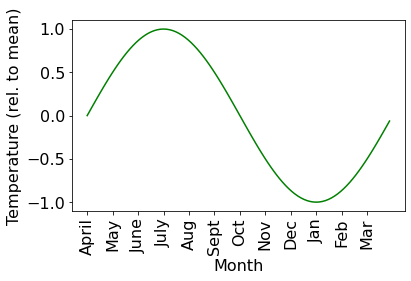

In [ ]:
# Your code here


To generate our real data, we want to add some noise to our `sin` function.

* Use `np.random.seed` and set the `seed=3`. This is so we all have the same random data.
* Add independent Gaussian noise with `std=0.15` to `y`. Call this noisy version of the `sin` function `t`.

🚩 **Common mistake:** `np.random.randn` draws noise with standard deviation 1, so it must be scaled by the desired `std`, and `np.random.seed` only affects draws made after it is called. Code that draws the noise before seeding, or that never scales it, runs without error but gives data that differs from everyone else's and from the plot shown.

In [ ]:
# Your code here


Now plot `t` alongside our `sin` function (at the `xplot` spacing)

Your plot should look like this:

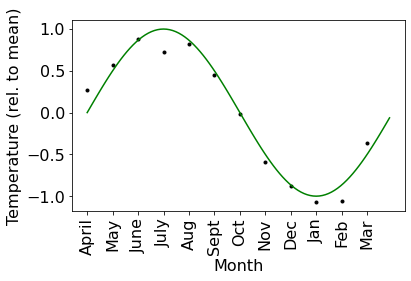

In [ ]:
# Your code here



---
### Part 2 (2 points)

We are going to take this opportunity to expand some of our python skills. We are going to work a bit more with [for loops](https://wiki.python.org/moin/ForLoop), [list comprehensions](https://docs.python.org/3/tutorial/datastructures.html#list-comprehensions), and [functions](https://docs.python.org/3/tutorial/controlflow.html#defining-functions).

We are going to work with this functionality within the context of a walkthrough of linear regression. This assignment will have you approximate the data we just generated above with linear combinations of polynomial functions. This is typically referred to as [polynomial regression](https://en.wikipedia.org/wiki/Polynomial_regression), which might seem like a nonlinear analysis (because we will be using higher-order polynomials) but is in fact linear because we *linearly* combine these nonlinear functions to predict the dependent variable `t`.

To prepare us to perform this regression, we have to get comfortable computing polynomial powers of `x`, our independent variable.

*  Write a `for` loop that creates a list in which each entry is a float equal to the **second order** polynomial (i.e. $(\cdot)^2$) of `x` (NOTE: *NOT* `xplot`). Check the documentation for dealing with [`lists`](https://docs.python.org/3/tutorial/datastructures.html#more-on-lists).

* Achieve the same goal by exloiting the vectorized functionality of numpy arrays. In other words, do you actually need to apply the squaring operation element by element, or is there a simplier way?

* Use the `==` expression to verify you get the same result either way you do it.



In [ ]:
# Your code here


Now

*  Write a **nested** `for` loop that creates a **list of lists** (🤯), in which each entry is a list of up to the n-th polynomial values of `x`, for orders 0 to 9.

* Achieve the same goal with a [list comprehension](https://docs.python.org/3/tutorial/datastructures.html#list-comprehensions).

* Confirm that they are equal using `np.array_equal`. (See [man page](https://numpy.org/doc/stable/reference/generated/numpy.array_equal.html))



In [ ]:
# Your code here


---
### Part 3 (2 points)

Functions make our lives much easier. When we write code that we use over and over again (as we are about to do) functions allow us to reuse the functionality we've written. We discussed the syntax of functions in lecture; if you need a reminder see: [`functions`](https://docs.python.org/3/tutorial/controlflow.html#defining-functions). Keep in mind that scoping is *NOT* the same in python as it is in matlab: see [here](https://www.datacamp.com/tutorial/scope-of-variables-python).

*  Write a function that takes `x` as an input and returns all polynomials up to order 9 of each entry of `x`.
* Execute the function to illustrate that it works. The output should be shape $10 \times 12$, so show that it is. (It is of dimension 10 becuase we are up to the 9-th order polynomial, and we are including the 0-th order.)



In [ ]:
# Your code here


---
### Part 4 (2 points)

Recall that to model our data `t` with linear regression, we assume that a linear combination of polynomials will approximately equal our data: $$t_i \approx bX_i,$$

where $t_i$ is the i-th data point, $b$ is a $n$-dimension array and $X_i$ is a $n$-dimensional array of the i-th datapoint of `x` to polynomials up to power $n-1$.

To fit this model, we will have to use some more advanced linear algebra in python than we have been using. We'll first start with the dot product between `b` and `X_i`.

*  Create an array of `n` coefficients of Gaussian random variables with `std=0.01`. Call this array `b0`. Don't worry that its random; we are going to optimize our model soon, so it doesn't matter what the entries are.

*  Write a function that takes `x` and `b` as an input and returns the [dot product](https://numpy.org/doc/stable/reference/generated/numpy.dot.html) of `b` with a matrix of all `x` values raised to polynomials of order $n - 1 = 9$. This function should use the function you defined previously for computing polynomial powers of `x`. The output should be of dimension 12 (for all 12 datapoints), so show that it is.

Recall that with linear regression, we want to find the $b$ the minimizes the sum of the squares of the difference between $t$ and $bX$:  $$J = \frac{1}{2}||t - bX||^2.$$ $J$ is typically referred to as an 'objective function'. (We will discuss later in this module why we use this particular critera for the objective function. For now just take it on faith that this is a good idea.)

*  Write a function that computes the sum of the squared difference between the $bX$ and our data $t$. This function should call the function you wrote previously for computing the dot product $bX$.

* Confirm that it returns a scalar value



In [ ]:
# Your code here


---
### Part 5 (2 points)

To compute the $b$ that minimizes our objective function we are going to perform [gradient descent](https://en.wikipedia.org/wiki/Gradient_descent). To do this, we need to compute the gradient of our objective function with respect to $b$: $\frac{\partial J}{\partial b}$.

*  Compute $\frac{\partial J}{\partial b}$ by hand. You don't need to show your work (unless you want to) because you will need to eventually code this up in python.

*  You may notice that your solution for $\frac{\partial J}{\partial b}$ has some complicated linear algebra operations. Here's a little practice for coding it up: compute the matrix product of `n-1` order polymials of `x` with its transpose and confirm it is of dimension $n \times n$.

*  Once you have computed $\frac{\partial J}{\partial b}$ by hand, write a python function that computes the gradient of our objective function given $t$, $x$, and $b$.

*  Confirm that it returns of vector of dimension `n`




In [ ]:
# Your code here


---
### Part 6 (2 points)

Now that we have python functions for our objective function and our gradient, we are ready to optimize $b$. Recall that the expression for gradient descent is: $$b_i = b_{i-1} - \alpha \frac{\partial J(t, x, b_{i-1})}{\partial b_{i-1}}.$$

*  Write a for loop to perform gradient descent. Use a step size of $\alpha = 0.1$. Take `20_000` gradient steps. Recall that we set the initial value of `b` above.

*  Compute the value of the objective at each iteration. Once your for loop is complete, plot the values of $J$ over the descent. As you might expect, it should go down: i.e. the difference between $t$ and $bX$ is getting smaller as we find a better $b$. Label your axes with something logical.

🚩 **Common mistake:** if you start with `b = b0` and then update `b` in place (e.g. `b -= alpha * grad`), NumPy modifies `b0` too, because both names refer to the same array. Later parts that reuse `b0` as the starting point then silently begin from the already-optimized values; use `b = b0.copy()`.

Your plot should look like this:



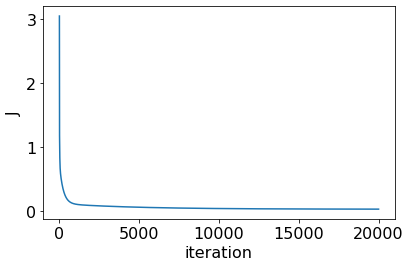

In [ ]:
# Your code here


---
### Part 7 (2 points)

Unlike more complicated models that we will get to later, linear regression is one of the most well-studied models, with strong guarantees regarding its optimization AND analytic forms for the minimizer.

* The analytic solution can be solved on paper and pencil by solving when $\frac{\partial J}{\partial b} = 0$. Compute this by hand. You don't need to show your work because you have to code it in python anyway.

*  Compute the closed form solution of OLS in python. [`numpy.linalg`](https://numpy.org/doc/stable/reference/routines.linalg.html) is your friend; be sure to import is as `import numpy.linalg as linalg`.

*  Plot the analytic solution as a line against the steps of gradient descent.

Your plot should look like this:

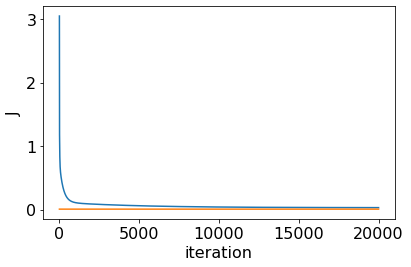

In [ ]:
# Your code here


---
### Part 8 (2 points)

One of the amazing things about python (and other open source languages) is the rich ecosystem of packages. These packages help us so we don't have to reinvent the wheel everytime we do an analysis. (Although, in this case, we wanted you all to do it from the ground up to learn something!)

Within the `linalg` submodule of `numpy` there is a function called `lstsq` for performing least squares regression. Check the [documentation](https://numpy.org/doc/stable/reference/generated/numpy.linalg.lstsq.html) about how to use it.

*  Perform regression using `lstsq`.
*  Plot the solution from `lstsq` as a line against the steps of gradient descent.

Your plot should look like this:

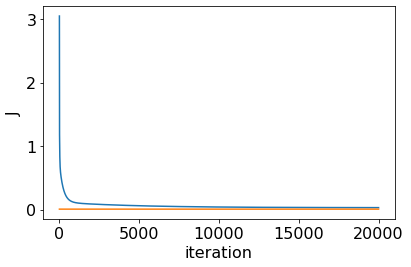

In [ ]:
# Your code here


---
### Part 9 (2 points)

Now that we've computed the optimal $b$ three ways, let's take a look at what it produces.

Plot:

* the data we used to fit the model, i.e. `t` and `x` as **dots**.
* the true underlying function `sin()` at the resolution of the `xplot` indices as a **green line**.
* $bX$ from our gradient descent solution, at `xplot` resolution as a **blue line**.
* $bX$ from our analytic solution at `xplot` resolution as a **cyan line**.
* $bX$ from our `lstsq` solution at `xplot` resolution as a **red dotted line**.
* Be sure to label your axes as we did above.
* Add a legend to keep the different lines clear.

<font color='red'>**SHORT ANSWER:** Describe the most prominent feature of the closed form and regression solution. (For the time being ignore anything you might notice about the gradient descent solution.) In what way is it qualitatively different than the `sin` function used to generate the data?

Your plot should look like this:

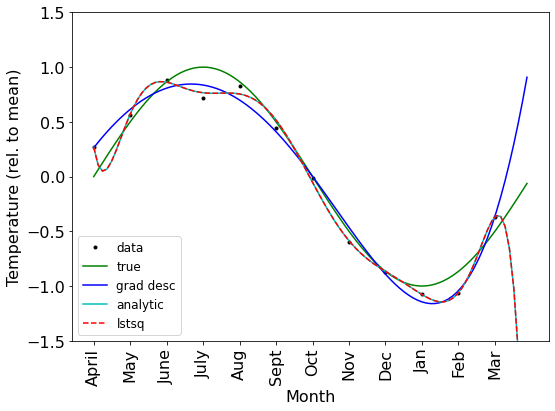

In [ ]:
# Your code here


To get a clearer picture how the sum of these polynomial functions produce an approximation to the `sin` function, plot some sums of the polynomials, increaseing from only the 0-th order entry, the 0-th and 1-st, etc. Plot the 0-th order only, 0-th through 3-rd order, and 0-th through 6-th order. Plot them in different colors so you can distinguish them, and also plot the data, and include a legend. Use the gradient descent least squares solution.

**You should notice that as we add higher order polynomails, we get closer to the data**.

Your plot should look like this:

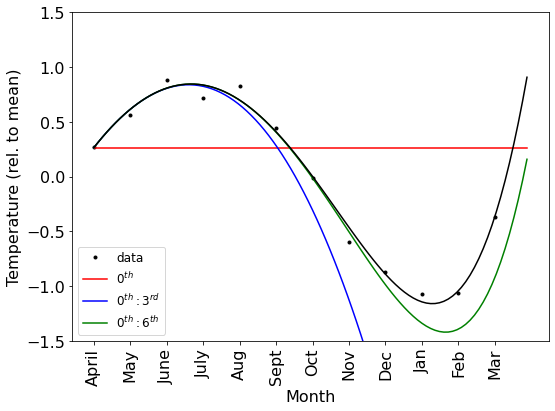

In [ ]:
# Your code here


---
### Part 10 (2 points)

Why did we select the learning rate for gradient descent to be what we did? Let's explore! Perform gradient descent again with a learning rate `100` times smaller. (See the power of writing functions now!??!)

<font color='red'>**SHORT ANSWER:** What do you notice that is different compared to the larger learning rate?

Plot the objective function across gradient iterations, as above, for both learning rates.

Your plot should look like this:

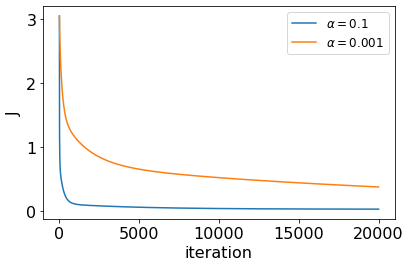

In [ ]:
# Your code here


---
### Part 11 (2 points)
Perform gradient descent ($\alpha = 0.1$), solve for the analytic form of ordinary least squares, and perform regression using `lstsq` **AGAIN** but this time, with polynomials up to order 3. (Note that you will have to reinitialize $b$, and change the number of coefficients in it.)

<font color='red'>**SHORT ANSWER:** What do you notice that is different compared to using polynomials up to order 9? This is an example of something we will discuss extensively throughout the rest of the module and is a critical concept in more advanced machine learning methods.

Plot the results of all three solutions for up to order 3 polynomial approximation, like we did above.

Your plot should look like this:

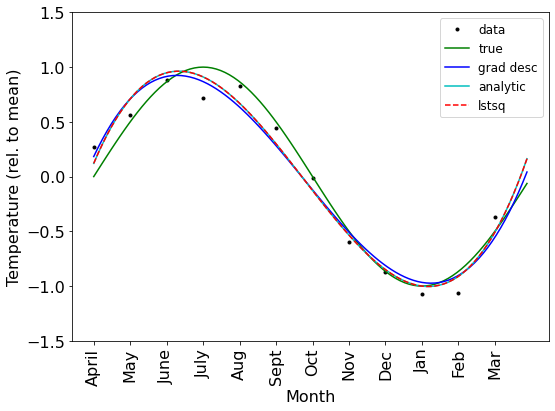

In [ ]:
# Your code here


---
### Part 12 (2 points)

Now, perform gradient descent ($\alpha = 0.01$), solve for the analytic form of ordinary least squares, and perform regression using `lstsq` **AGAIN** with polynomials up to order 9, **BUT** with the data at `xplot` resolution.(Note that you will have to reinitialize $b$, and change the number of coefficients in it.)

**NOTE**: You have to regenerate $t$ for the case when we have more data. Use `seed=3` again and generate the **noisy** data just as we did before.

**Notice** that we are now using 100 datapoints (10 times as many)!

<font color='red'>**SHORT ANSWER:** What do you notice that is different compared to using only 10 datapoints, when using polynomials up to order 9? This is also an example of something we will discuss extensively throughout the rest of the module and is a critical concept in more advanced machine learning methods.

Plot the results of all three solutions like we did above.

Your plot should look like this:

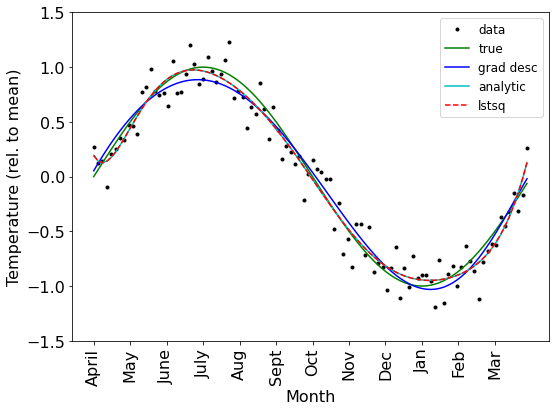

In [ ]:
# Your code here


---
## Final thoughts

We increased and decreased the number of polynomials we used to fit our model AND we increased and decreased the amount of data, and we saw different results that depended on these choices. Guess, if you can, how these things are related to each other in this model. Comment on outcomes with varying amounts of data and polynomials in the fit and how these two factors relate to each other.

In [ ]:
# Your code here


## Homework 2.2 (20 points)

**Learning objectives:**

In this assignment, we will:

* Continue to exercise our skills in more advanced python features (functions, list comprehensions)
* Fit models to data with regularized least squares regression
* Perform cross-validation to find the best predictive model
* Analyze how cross-validation performance changes with model complexity, and how model complexity can be controlled by regularization

---
Load the same libraries that we used in *Assignment 2.1*.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)

Now is also a good time to set the default font size to 16.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({'font.size': 16})

---
### Part 1 (1 points)
Regenerate our `sin` data from assisgnemtn 2.1:

* use [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html#numpy.linspace), to generate a set of 12 time indices and call it `x`. For simplicity have those indices range from 0 to 1 - $\frac{1}{12}$ (subtract the $\frac{1}{12}$ so the indices don't loop back onto themself.

* Use `np.sin` to create a set of 12 temperature measurements called `y`. Be sure to set the frequency to a period of 1 year.

* For plotting purposes, we want to sample time more densely. So create another time index array (call it `xplot`). Use np.arange to create a time index vector from 0 to 1 in steps of 0.01.

* Use `np.random.seed` and set the `seed=3`. This is so we all have the same random data.

* Add independent Gaussian noise with `std=0.25` to `y`. Call this noisy version of the `sin` function `t`. NOTE THE LARGER STD.

* Plot xplot vs np.sin(xplot) (with appropriate frequency). It should look like you expect :)

* Label the xlabel with month, the ylabel with Temperature. Use plt.xticks to re-label the xticks with the months starting from April and also rotate the labels so you can read them.

* Plot `t` alongside our `sin` function (at the `xplot` spacing)

**Your plot should look like this:**

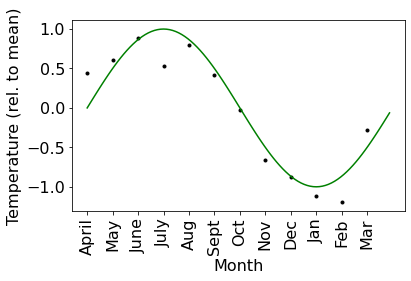

In [ ]:
# Your code here


---
### Part 2 (2 points)

Regenerate several of our helpful functions from assignment 2.1.

*  Write a function that takes `x` and `n` as an input and returns all polynomials up to order `n-1` of each entry of `x`.

* Write a function that takes `x` and `b` as an input and returns the [dot product](https://numpy.org/doc/stable/reference/generated/numpy.dot.html) of `b` with a matrix of all `x` values raised to polynomials of order $n - 1$. This function should use the function you defined previously for computing polynomial powers of `x`. The output should be of dimension 12 (for all 12 datapoints).

* Write a function that computes the squared difference between the $bX$ and our data $t$ (i.e., our objective function). This function should call the function you wrote previously for computing the dot product $bX$.

* Write a function that computes the analytic solution for ordinary least squares. [`numpy.linalg`](https://numpy.org/doc/stable/reference/routines.linalg.html) is your friend; be sure to import is as `import numpy.linalg as linalg`.




In [ ]:
# Your code here


---
### Part 3 (1 points)

To perform cross-validation we need data for training the model, and then **new** data to test the model. Generate a new dataset called `ttest` by adding new random noise to `y`. Use `seed=4`.

🚩 **Common mistake:** `ttest` should be the noiseless `y` plus new noise, not `t` plus noise. Adding to `t` gives test data carrying both noise draws (larger variance), and the test error will come out wrong without any error message.

In [ ]:
# Your code here


---
### Part 4 (4 points)

In assignment 2.1, we began to see the signs of overfitting: overly complex models will fit the training data **too** well. Let's explore this more quantitatively.

* Using a list comprehension and your function for the analytic least squares solution, compute the set of coefficients (i.e., `b`) that minimizes our objective function over a range of models that use polynomials ranging from only the 0-th order polynomial, to a model that includes up to the 9-th order polynomial of `x`.

* Using a list comprehension and your function for the value of the objective function, compute the model error over the training data, for all your models.

* Using a list comprehension and your function for the value of the objective function, compute the model error over the **test** data, for all your models.

* Plot the training (in red) and test (in blue) error as a function of model complexity. Labels the axes and include a legend.

<font color='red'>**SHORT ANSWER:** What do you notice about the falloff in error for the training data, and for the testing data, respectively?

**Your plot should look like this:**



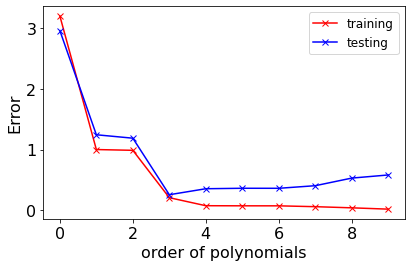

In [ ]:
# Your code here


---
### Part 5 (2 points)

Let's take a look at the different models we fit, depending on the error of the model.

* Use two subplots.

* In the left subplot, plot the training data (with black dots) and the model that minimizes the training error (in red) and the testing error (in cyan).

* In the right subplot, plot the test data (with blue x's) and the model that minimizes the training error (in red) and the testing error (in cyan).

* Labels the axes and include a legend.

<font color='red'>**SHORT ANSWER:** What do you notice about the different model fits when comparing them against the training data and the testing data, respectively?

**Your plot should look like this:**

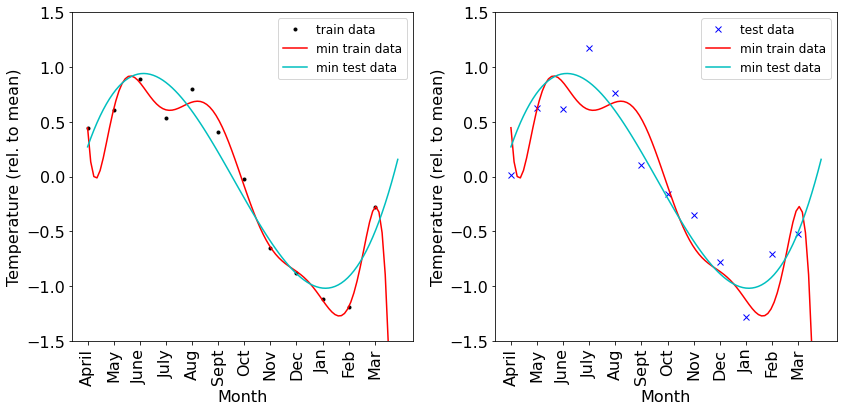

In [ ]:
# Your code here


---
### Part 6 (2 points)

Above, we have shown that testing error will increase if our model is too complex. This means that we are not doing as good a job predicting new data as we could with a simpler model. In lecture, we discussed how regularization can maintain model simplicity while still predicting the data.

Recall that the regularized least sqaures objective function is: $$J = \frac{1}{2}||t - bX||^2 + \frac{\lambda}{2}||b||^2,$$ where $\lambda$ is a parameter that controls how strong the regularizing term is.

In class, we analyticaly computed the value of $b$ that minimizes this objective function. Write a python function that computes $b$.



In [ ]:
# Your code here


---
### Part 7 (4 points)

Recall from lecture that in order to pick the value of $\lambda$ that finds the simplest model, we have to scan over values of $\lambda$ and find the one that minimzes the test error.

* Using a list comprehension and your function for the **regularized** analytic least squares solution, compute the set of coffeficients (i.e., `b`) that minimizes our objective function over a range of models that use values of $\lambda$ that range from $10^{-14}$ to $10^{13}$.

* Using a list comprehension and your function for the value of the objective function, compute the model error over the training data, for all models with different values of $\lambda$.

* Using a list comprehension and your function for the value of the objective function, compute the model error over the **test** data, for all models with different values of $\lambda$.

* Plot the training (in red) and test (in blue) error as a function of $log_{10}(\lambda)$. Labels the axes and include a legend.

<font color='red'>**SHORT ANSWER:** What do you notice about the falloff in error for the training data, and for the testing data, respectively?

**Your plot should look like this:**


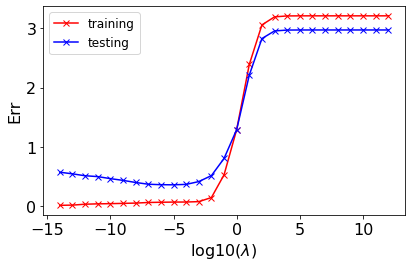

In [ ]:
# Your code here


---
### Part 8 (2 points)

Let's take a look at the different models we fit, depending on the error of the model.

* Use two subplots.

* In the left subplot, plot the training data (with black dots), the model that minimizes the training error (in red), the model that minimizes the testing error (in cyan), and the model with the largest value of $\lambda$ (i.e, in the most regularized model; in green).

* In the right subplot, plot the test data (with blue x's) and the model that minimizes the training error (in red), the model that minimizes the testing error (in cyan), and the model with the largest value of $\lambda$ (i.e, in the most regularized model; in green).

* Labels the axes and include a legend.

<font color='red'>**SHORT ANSWER:** What do you notice about the models fits for the training data and the testing data, respectively? What do you notice about the most regularized model?

**Your plot should look like this:**

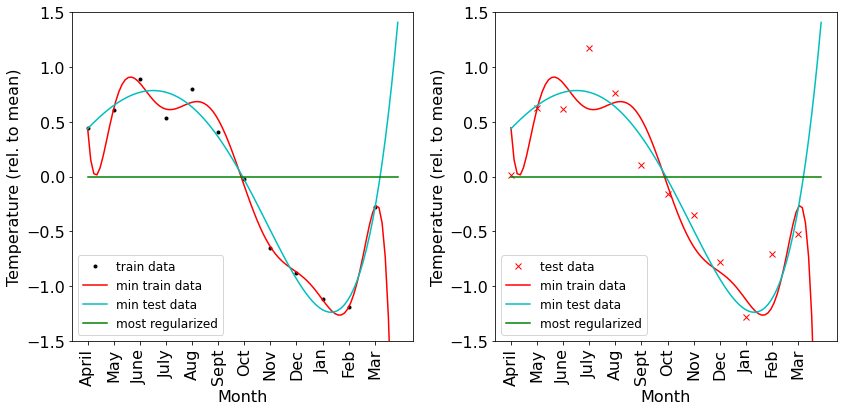

In [ ]:
# Your code here


---
### Part 9 (2 points)

What is regularization doing? One way to see this is to examine the coefficients of $b$ for each model.

* Plot the $b$ weight values (polynomial order on the x-axis, log-scaled value on the y axis) for the following 3 models: the model that minimizes the training error (in red), the model that minimizes the test error (in cyan), and the model with the largest value of $\lambda$ (i.e, in the most regularized model; in green).

* Labels the axes and include a legend.

<font color='red'>**SHORT ANSWER:** What do you notice about the model that best fits the training data? What about the one that best fits the testing data? What do you notice about the most regularized model?

**Your plot should look like this:**

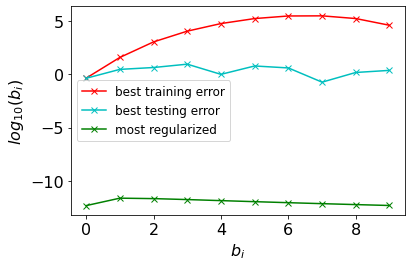

In [ ]:
# Your code here


In [ ]:
# Your code here


## Homework 2.3 (42 points)

**Learning objectives:**

In this assignment, we will:

* Continue to strengthen our understanding of gradient descent, especially how regularization influences our gradient updates.
* Take a quick crash course through python objects, methods, and attributes, so that we can use scikit-learn.
* Fit ridge regression, lasso, and logistic regression with scikit-learn!

---
Load the libraries we've been using, and set the default font size to 16.

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'font.size': 16})

---
### Part 1 (1 points)

We are going to dig in to one more gradient descent example, this time for case in which we do ridge regression, to hopefully get a better feel for what the regularization term in ridge is doing.

Let's generate some synthetic data, like in our homework, but much simplier. Actually, we are going to follow the exact same example as in the [gradient descent tutorial](https://colab.research.google.com/drive/10WUSP0aq3CaiUXYuYcqXFnV7Tar1q6P0?usp=sharing) that was posted last week.

* use [`np.linspace`](https://numpy.org/doc/stable/reference/generated/numpy.linspace.html#numpy.linspace), to generate a set of `x` 100 values from -5 to 5.

* Define a parameter `bstar=2` that we want to use to generate data, and that we will try to find using least squares.

* Create a set of `y` values such that `y=bstar*x`.

* Add independent Gaussian noise with `std=1` to `y`. Call this noisy version `t`. Use `np.random.seed` and set the `seed=3`. This is so we all have the same random data.

* For plotting purposes, we want to sample time more densely. So create another time index array (call it `xplot`). Use np.arange to create a time index vector from -5 to 5 in steps of 0.01.

* Plot `xplot` vs `bstar*xplot`, and label the axes appropirately.

**Your plot should look like this:**

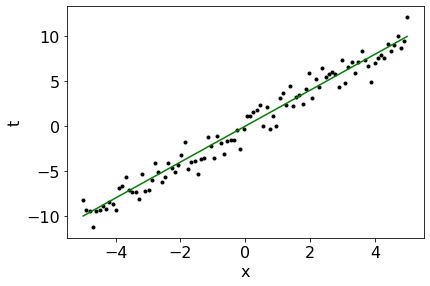

In [ ]:
# Your code here


---
### Part 2 (2 points)

Recall that the regularized least squares objective function is: $$J = \frac{1}{2}||t - bX||^2 + \frac{\lambda}{2}||b||^2,$$ where $\lambda$ is a parameter that controls how strong the regularizing term is.

* Write a python function that computes `J` for ridge regression.

* Define a parameter `lam` (i.e. $\lambda$) and set is to 1e-6, i.e. a very weak regularization.

* Scan over a range of `b` (call it `bplot`) from 1.5 to 2.5, and plot the objective function vs. those values.

As expected, `J` should be a quadratic function of `b`. And it looks like the lowest point of J is very very close to 2. Which it should be! bstar = 2 and our regularization term $\lambda$ is very small. Remember that the point of gradient descent is to find bstar when we dont' know it.

**Your plot should look like this:**




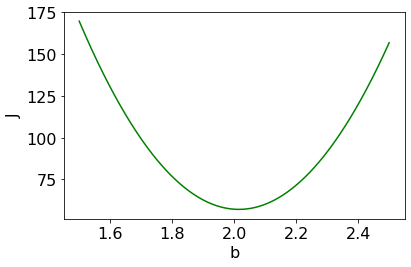

In [ ]:
# Your code here


---
### Part 3 (2 points)

* Write a python function that computes the gradient of `J` for ridge regression. (See lecture 2.2 for the correct equation. Or better yet, try to compute it yourself from `J` defined above!).

**Have your function return the gradient in TWO SEPERATE PARTS: the component that corresponds to the normal least squares component of the objective, and the part that corresponds to the regulariation term. See the gradient descent tutorial for an example that has the gradient only for the unregularized least squares solution.**

* Pick a random initial `b=2.5`, as our starting point for gradient descent, pretending we don't know where `bstar` actually is.

* Perform 200 iterations of gradient descent with learning rate of `alpha=0.0001`. Save the values of `b`, `J`, and both terms of the gradient **multiplied by `alpha`** for each iteration.

In [ ]:
# Your code here


---
### Part 4 (2 points)

* Plot `bplot` vs `J` for the values of `J` you computed above (i.e. J as a function of `bplot`) as a function of `bplot`, as a *green line*.
* Plot `b` vs. `J` for the values you obtained during gradient descent as *black dots* on top of your green line. They should look like the are moving towards `bstar`.
* In a second plot, plot `b` as a function of the gradient descent iteration. Is it approaching `bstar`?

**Your plots should look like this:**

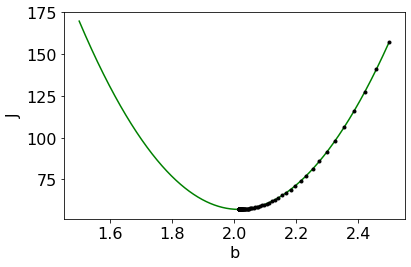

In [ ]:
# Your code here


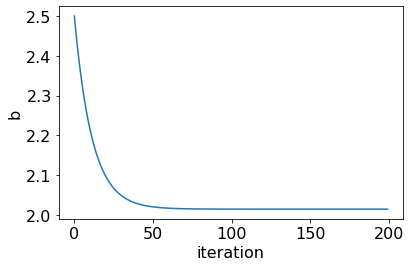

In [ ]:
# Your code here


---
### Part 5 (2 points)

We want to now examine gradient descent with stronger regularization.

* Set `lam=1e2`.

* Scan over a range of `b` (i.e. `bplot` that you created above) and plot the objective function vs. those values for our objective function we use use `lambda=1e2`.

* Perform 200 iterations of gradient descent with learning rate of `alpha=0.0001`. For each value of `b` compute the value of `J` for ridge regression using `lam=1e2` and ALSO the value of the **UNCONSTRAINED** least squares objective (i.e. the value of our objective function when `lam=0`). Save the values of `b` and both terms of the gradient for each iteration, and also values of `J` for both cases.

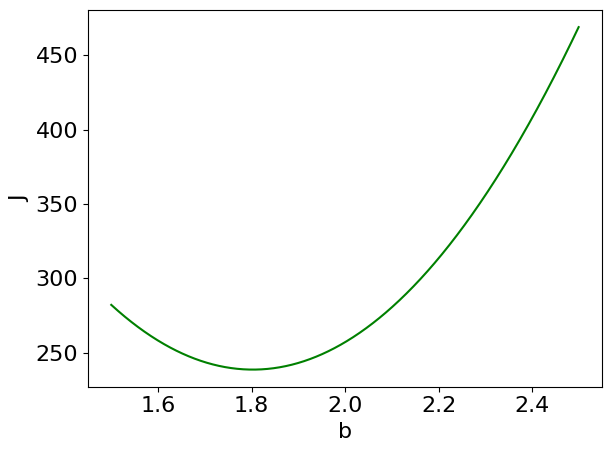

In [ ]:
# Your code here


---
### Part 6 (2 points)

* Plot `bplot` vs `J` for the values of `J` you computed above (when using `bplot` and `lam=1e-6`), as a function of `bplot`, as a *green line*.
* Plot `bplot` vs `J` for the values of `J` you computed above (when using `bplot` and `lam=1e2`), as a function of `bplot`, as a *green dotted line*.
* Plot `b` vs. `J` for the values of `J` and `b` you obtained during gradient descent when b was used **IN THE UNCONSTRAINED OBJECTIVE** (i.e. `lam=0`) as *black dots* on top of your **green line**. They should look like the are moving towards `bstar`, but then they go right past it!
* Plot `b` vs. `J` for the values of `J` and `b` you obtained during gradient descent **ON THE CONSTRAINED OBJECTIVE** (i.e. when `lam=1e2`) as *black stars* on top of your **green dotted line**. They should look like the are moving towards `bstar`, but then they go right past it!

<font color='red'>**SHORT ANSWER:** What do you notice about the difference between the this regularized solution and the one you computed above with very weak regularization? Why do the values of `b` pass right by `bstar`?

**Your plot should look like this:**

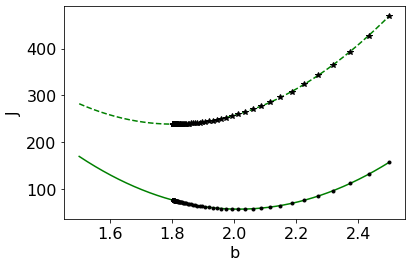

In [ ]:
# Your code here


---
### Part 6 (1 point)

Plot `b` found during gradient descent as a function of the gradient descent iteration when `lam=1e-6` and when `lam=1e2`.

**Your plot should look like this:**

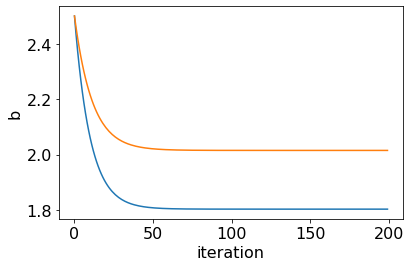

In [ ]:
# Your code here


---
### Part 7 (4 points)

Using two subplots, plot the two separate components of the gradient (the term corresponding to the unconstrained component as stars (`*`) and the term corresponding to the regularization component as a dotted line) and the sum of the two components as a solid line. Plot these values for the gradients when `lam=1e-6` in blue on the left and when `lam=1e2` in red on the right.

<font color='red'>**SHORT ANSWER:** What do you notice about the two seperate terms for `lam=1e2`? How do these terms relate to each other, numerically? What does it mean that they have opposite signs of one another?

**Your plot should look like this:**

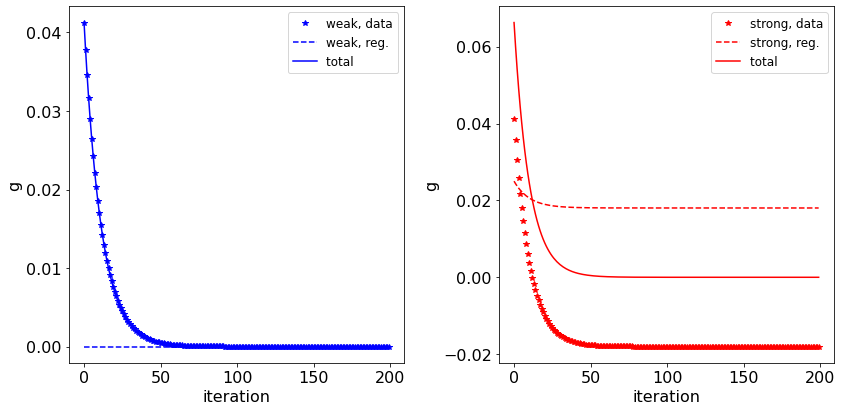

In [ ]:
# Your code here


---
### Part 8 (0 points)

One way to understand what's going on here is to plot each component of the gradient as a line pointing in the direction it wants to pull `b`, overlayed over our plots that looked at how `b` changed during gradient descent. Like so:

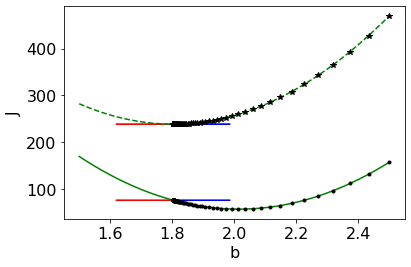

In [ ]:
fig, ax = plt.subplots()

plt.plot(bplot, J, 'g-')
plt.plot(bplot, J2, 'g--')
plt.plot(bs2, Js2, 'k.')
plt.plot(bs2, Js3, 'k*')

plt.arrow(x=bs2[-1][0], y=Js3[-1], dx=(10*gs2[0,-1]), dy=0, width=0.001, color="red")
plt.arrow(x=bs2[-1][0], y=Js3[-1], dx=(10*gs2[1,-1]), dy=0, width=0.001, color="blue")

plt.arrow(x=bs2[-1][0], y=Js2[-1], dx=(10*gs2[0,-1]), dy=0, width=0.001, color="red")
plt.arrow(x=bs2[-1][0], y=Js2[-1], dx=(10*gs2[1,-1]), dy=0, width=0.001, color="blue")

plt.ylabel('J')
plt.xlabel('b');
plt.tight_layout();

What we can see from this that each term is pulling `b` in opposite directions, and when gradient descent converges, those two terms are equal and opposite. In the **CONSTRAINED** objective function, that corresponds to a minimum. In the **UNCONSTRAINED** funcdtion (which is simply PART of the constrained function) is does not -- because the regularization term is pulling it away!

---
### Part 9 (1 points)

We will now switch gears a bit and use [scikit-learn](https://scikit-learn.org/stable/) to fit [lasso](https://en.wikipedia.org/wiki/Lasso_(statistics)) on the prostate cancer dataset introduced in class. Scikit-learn is a super helpful machine learning python library that can perform lots of standard but algorithmically challenging analyses so you don't have to write them all from scratch! Yippee!!

* First thing we need to do is load our prostate cancer dataset. These data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/empathy87/The-Elements-of-Statistical-Learning-Python-Notebooks/master/data/Prostate%20Cancer.txt

To do this, use the `genfromtxt` function in numpy (i.e. `np.genfromtxt`) to load the data directly from this URL into a variable called `data`.  Since this is a .csv file, you will need to set the delimeter to ',' (a comma in single quotes).  The first row in the file contains column labels.  You can use the option `skip_header=1` to skip the first line and only read the numerical data.


In [ ]:
# Your code here


Some of the columns of this array contain features of the data that we don't need. Use the [np.delete](https://numpy.org/doc/stable/reference/generated/numpy.delete.html) function to create a new array called `X` that does not include the 1st, 2nd to last, and final columns of `data`.

In [ ]:
# Your code here


---
### Part 10 (2 points)

In class, we discussed the [correlation matrix](https://en.wikipedia.org/wiki/Correlation#correlation%20matrices), which are simply the correlation values of all pairs of your independent variables.

* Create a list of strings for each of the dependent variables: `lcavol`, `lweight`, `age`, `lbph`, `svi`, `lcp`, `gleason`, `pgg45`.

* Use the `numpy` method [`corrcoef`](https://numpy.org/doc/stable/reference/generated/numpy.corrcoef.html) to compute the correlation matrix. Note that you may have to take the transpose of `X`; your correlation matrix should have dimensions equal to the number of independent variables, not the number of data samples.

* Use the `matplotlib` function [`imshow`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.imshow.html) to plot your correlation matrix. Label each row and column with the appropriate name of each variable.

<font color='red'>**SHORT ANSWER:** Are `lcp` and `lcavol` strongly correlated, like they were in lecture? Print the value of the correlation between these two dependent variables.

**Your plot should look like this:**



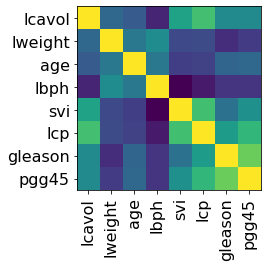

In [ ]:
# Your code here


---
### Part 11 (1 points)

[Pandas](https://pandas.pydata.org/) is another python package that we will make use of in the future. It can be especially useful for looking at structured data arrays, and computing some simple statistics on them. We won't use it extensively here, just a quick peek at it.

* Import the pandas library into python as `pd`.
* Use the [dataframe](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.html) method to create a tabular dataframe called `df` for our data. The `columns` argument should be equal to the list of features we created above. No other arguments are required, beyond the data itself, `X` and `columns`.

* Use the [`dataframe.head()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html) method to show the first `n=10` rows of your dataframe `df`.

**Your dataframe should look like this:**

In [ ]:
# Your code here


,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45
0,-0.579818,2.769459,50.0,-1.386294,0.0,-1.386294,6.0,0.0
1,-0.994252,3.319626,58.0,-1.386294,0.0,-1.386294,6.0,0.0
2,-0.510826,2.691243,74.0,-1.386294,0.0,-1.386294,7.0,20.0
3,-1.203973,3.282789,58.0,-1.386294,0.0,-1.386294,6.0,0.0
4,0.751416,3.432373,62.0,-1.386294,0.0,-1.386294,6.0,0.0
5,-1.049822,3.228826,50.0,-1.386294,0.0,-1.386294,6.0,0.0
6,0.737164,3.473518,64.0,0.615186,0.0,-1.386294,6.0,0.0
7,0.693147,3.539509,58.0,1.536867,0.0,-1.386294,6.0,0.0
8,-0.776529,3.539509,47.0,-1.386294,0.0,-1.386294,6.0,0.0
9,0.223144,3.244544,63.0,-1.386294,0.0,-1.386294,6.0,0.0


---
### Part 12 (1 points)

* Use the [`dataframe.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) method to again compute the correlation matrix of your indepedent variables that are organized within `df`.

<font color='red'>**SHORT ANSWER:** Are the correlation matrices the same when you use `numpy` and when you use `pandas`? Good!

**Your dataframe should look like this:**


In [ ]:
# Your code here


,lcavol,lweight,age,lbph,svi,lcp,gleason,pgg45
lcavol,1.000000,0.280521,0.225000,0.027350,0.538845,0.675310,0.432417,0.433652
lweight,0.280521,1.000000,0.347969,0.442264,0.155385,0.164537,0.056882,0.107354
age,0.225000,0.347969,1.000000,0.350186,0.117658,0.127668,0.268892,0.276112
lbph,0.027350,0.442264,0.350186,1.000000,-0.085843,-0.006999,0.077820,0.078460
svi,0.538845,0.155385,0.117658,-0.085843,1.000000,0.673111,0.320412,0.457648
lcp,0.675310,0.164537,0.127668,-0.006999,0.673111,1.000000,0.514830,0.631528
gleason,0.432417,0.056882,0.268892,0.077820,0.320412,0.514830,1.000000,0.751905
pgg45,0.433652,0.107354,0.276112,0.078460,0.457648,0.631528,0.751905,1.000000


---
### Part 13 (1 points)

Just to prove to yourself that you've 'earned' the right to graduate to using scikit-learn, let's check that the solution it provides when we perform ridge regression is the same that we know how to compute ourselves.

* Our dependent variable `lpsa`	(log prostate specific antigen) is the second to last entry of our data matrix `data`. Create a variable `t` that is equal to that column of `data`.

* Import the [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html) function from `sklearn.linear_model`.




In [ ]:
# Your code here


---
### Part 14 (2 points)

Python is an object oriented language, so it works a little differently than Matlab. With Scikit-learn, we are going to be seeing a lot more of this.

* Use the `Ridge` function to create what is called an 'instance of an object' class, and call this instance `clf`. For arguments to `Ridge` use `alpha=1.0` (i.e. weak regulariztion) and `fit_intercept=False` (i.e. don't learn a constant term). Note that when we wrote the ridge objective function down we used $\lambda$ as the coefficient that controls the strength of regularization, but scikit-learn calls this parameter `alpha`.

Notice that after we do this, we haven't actually done anything yet, just created a sort of 'container' called an object instance, that we will later do stuff on.


In [ ]:
# Your code here


---
### Part 15 (2 points)

In an object oriented language, once you've created an instance of something, that thing has 'methods' associated with it. Methods are functions that can do things on that object. The way to 'call' a method associated with an instance of a object is to use a `.` after the instance: i.e. `object.method()`

* Use the `fit` method on your `clf` object instance class using `X` and `t` as data. See the documentation from `Ridge` for additional documentation for each method associated with an instance of ridge, such as [`fit`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge.fit).

Now we actually did something to `clf` -- we fit it using our data!



In [ ]:
# Your code here


Ridge(fit_intercept=False)

Object instances also have what are knowns as attributes, which are kind of like 'stuff' inside the object that you might want to know something about. The way to see an attribute, confusingly, is also to use a `.`, i.e. `object.attribute`. This can be confusing at first (i.e. how do you know what is an attribute and what is a method!?) but it will get easier with time.

* A ridge instance has an attribute called `coef_` which is the coefficients of the model. Print out `clf.coef_`.

In [ ]:
# Your code here


array([ 0.55869858,  0.60999902, -0.01933688,  0.09273029,  0.68885563,
       -0.08888248,  0.06981158,  0.00404428])

---
### Part 16 (2 points)

We know how to find the coefficients of a ridge regression model! Go back to assignment 2.2 and find your function for the analytical solution for ridge regression. Use that function, with `lambda=1.0` (i.e. `alpha` in scikit-learn language) to show that the solution you get with your homebrewed function is the same as what we get with scikit-learn.

**Your results should look like this:**




In [ ]:
# Your code here


array([ 0.55869858,  0.60999902, -0.01933688,  0.09273029,  0.68885563,
       -0.08888248,  0.06981158,  0.00404428])

---
### Part 17 (2 points)

Now that we have our feet a bit wet with python objects, methods, and attributes, we are ready to harness the power of scikit-learn for fitting our lasso model! Good thing we don't have to optimize the parameters of the lasso model ourselves -- what a pain!

* Import the [`Lasso`](https://scikit-learn.org/stable/modules/classes.html#module-sklearn.linear_model) function from `sklearn.linear_model`.

Recall that the Lasso objective function is $$J = \frac{1}{2}||t - bX||^2 + \frac{\lambda}{2}\sum_i |b_i|,$$

* Use the `Lasso` function to create an 'instance of an object' class, and call this instance `clf`. For arguments to `Lasso` use `alpha=0.1`. Again, scikit-learn `alpha` is our $\lambda$ from above.

* Use the `fit` method on your `clf` object instance class using `X` and `t` as data. See the documentation from `Lasso` for additional documentation for each method associated with an instance of Lasso, such as [`fit`](
 https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Lasso.html#sklearn.linear_model.Lasso.fit).

* A Lasso instance has an attribute called `coef_` which is the coefficients of the model. Print out `clf.coef_`.

Was that easy or what!?

**Your results should look like this:**


In [ ]:
# Your code here


array([ 0.57789584,  0.04282022, -0.00555591,  0.07637548,  0.        ,
        0.        , -0.        ,  0.00671169])

---
### Part 18 (2 points)

Let's check out how the coefficients of the Lasso model change as we increase or decrease the severity of the regulariation.

* Use a list comprehension to compute the Lasso coefficients when `alpha` (i.e. $\lambda$) ranges from `0.001` to `0.93`. Use 100 different values of alpha within that range.

* Plot the values of each coefficient as a function of the sum of all cofficients for that setting of `alpha`. Add a legend so you can see which parameter is which. Make your plot big so you can see everything clearly.


<font color='red'>**SHORT ANSWER:** `lcp` was the feature that we noticed was correlated with `lcavol`. What happens to the coefficient for `lcp` was the regularization is increased?

**Your plot should look like this:**


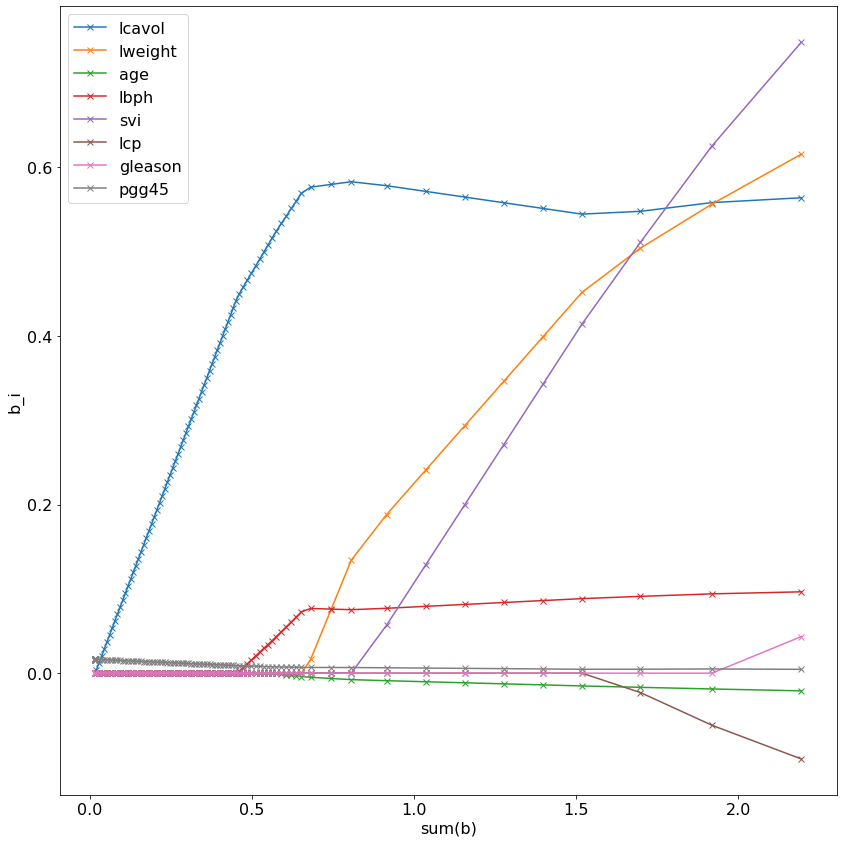

In [ ]:
# Your code here


---
### Part 19 (2 points)

Now that we are experts in using objects in python, and using scikit-learn, lets give logistic regression a try with it!

First we have to create some fake data that we are going to fit our model to. (As we have been doing, for didactic purposes). In lecture 2.5, I described a behavioral experiment where rats listen to a series of auditory pulses, and they have to 'count' how many pulses are to their left and right, and then make a choice depending on if there were more left or right pulses. Let's model this simple decision making task.

* Create 1000 'trials' of behavioral data, by creating two arrays, `L` and `R` that each contain the number of leftward or rightward pulses on a trial. To do this, use the numpy function [`random.randint`](https://numpy.org/doc/stable/reference/random/generated/numpy.random.randint.html). Use `-4` as your lower limit and `4` as your upper limit.

* Stack these two arrays on top of each other to create a 2 by 1000 array called `x`. Use the numpy function [stack](https://numpy.org/doc/stable/reference/generated/numpy.stack.html).

In [ ]:
# Your code here


---
### Part 20 (2 points)

Recall that in our logistic regression model, these independent variables relate to the probability of a discrete event (i.e. a 0 or 1, which in our model here corresponds to which way the animal chose) by a [logistic function](https://en.wikipedia.org/wiki/Logistic_function): $$Pr(t_i = 1) = y_i = f(x_i)$$.

* We need some coefficients $b$ to combine the left and right clicks with, to generate $y_i$. Choose this to be `bstar` and set `bstar = [-1,1]`. This corresponds to left pulses _decreasing_ the probability of a rightward choice (becuase the first term is -1) and right pulses _increasing_ the probability of a rightward choice (because the second term is +1).

* Compute the dot product of `bstar` and `x` and call it `X`, i.e $X_i = b^*x_i$. This is the total input into our logistic function, and can be helpful for understanding the relationship between the inputs to the logistic function and its output.

* Plot the output of the logistic function with `X` as its input, i.e. $$y_i = \frac{1}{1+exp(-X_i)}$$. Use dots or stars in your plot instead of lines (otherwise it will look like a total jumble).

**Your plot should look like this:**

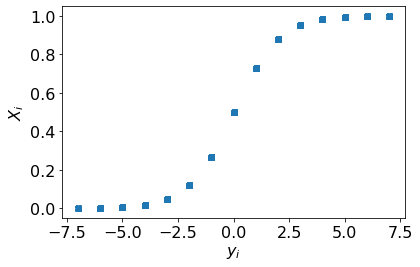

In [ ]:
# Your code here


---
### Part 21 (2 points)

To generate our data, which is corrputed by noise, we need to draw random samples from a Bernoulli distribution, using `y` as the probability that each datapoint is a 0 or a 1. In other words, recall that each datapoint $t_i$ is distributed Bernoulli: $$ t_i \sim B(y_i)$$ where $$y_i = f(x_i)$$ and $f()$ is the logistic function.

* Using `scipy.stats` to do this. The [`Bernoulli`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.stats.bernoulli.html) distribution is what you want to use.

* Revisit some of Module 1's assignments (such as 1.3) if you've forgotten how to use `scipy.stats` and `rvs`.

In [ ]:
# Your code here


---
### Part 22 (2 points)

To get a sense of how the noisy data (i.e. t_i) relates to the probability of the data (i.e. y_i) plot `X` vs `y` as above and overlay it with two histograms, one for the `X` values when `t=0` and one for the `X` values when `t=1`. For [hist](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.hist.html) use the arguments `density=True` and `alpha=0.5`.

<font color='red'>**SHORT ANSWER:** What do you notice about the distributions whe `t=1` and `t=0`?

**Your plot should look like this:**

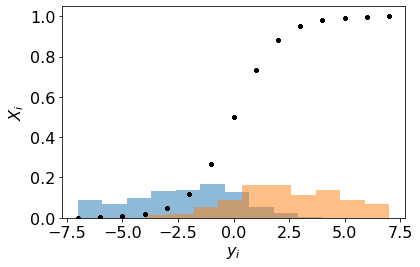

In [ ]:
# Your code here


---
### Part 23 (2 points)

OK let's recover `bstar` from our data using scikit-learn's [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression).

* Import scikit-learn's [Logistic Regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression) class as `LogisticRegression`.

* Use the `LogisticRegression` function to create an 'instance of an object' class, and call this instance `clf`. For arguments to `LogisticRegression` use `penalty='none'` and ` fit_intercept=False`.

* Use the `fit` method on your `clf` object instance class using `x` and `t` as data. See the documentation from `LogisticRegression` for additional documentation for each method associated with an instance of `LogisticRegression`, such as [`fit`](
https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html#sklearn.linear_model.LogisticRegression.fit). Note tht you may to take the tranpose of `x` if the dimensions don't work out correctly.

* A LogisticRegression instance has an attribute called `coef_` which is the coefficients of the model. Print out `clf.coef_`.

<font color='red'>**SHORT ANSWER:** Did `LogisticRegression` recover `bstar`?

**Your results should look like this:**

In [ ]:
clf.coef_

array([[-1.00792295,  1.0125503 ]])